# Another instrument: a model fitted on one spectrometer reads the spectra of another

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/18_another_instrument.ipynb)

The sixteenth notebook ended with a warning: a model of spectra learns the bands of the method
that made its spectra, and it fails on spectra from another method. In a laboratory the other
method is another **instrument**. A model is calibrated on one spectrometer, and then the
spectrometer is replaced, or a second one is bought for another site. Measuring every sample
again on the new instrument is expensive. Moving the model to the new instrument is called
**calibration transfer**.

This notebook uses the two near-infrared sets on which the methods of calibration transfer are
usually compared. In both, the same samples were measured on every instrument:

- **corn**: 80 samples on three spectrometers (`m5`, `mp5`, `mp6`), 700 points from 1100 to
  2498 nm, with four measured properties (moisture, oil, protein and starch);
- **tablets**: 655 tablets of the 2002 shoot-out on two spectrometers (1 and 2), with the
  content of the active ingredient (the assay).

The archive of Eigenvector Research states no licence for them, so no file of the sets is in the
repository. The first run of the notebook downloads them (6.5 MB) into
`benchmarks/cache/calibration_transfer`.

A model is fitted on the spectra of one instrument, the **source**. It then predicts new samples
from their spectra on another instrument, the **target**. The error is a root-mean-square error
divided by the standard deviation of the property, so a model that predicts the mean has an
error of about 1. The notebook asks four questions.

1. What differs between the spectra of one sample on two instruments?
2. How badly does a model read the spectra of the other instrument, and what repairs it without
   any sample measured on both instruments?
3. Does a correction of every spectrum by itself, the usual first step of a chemometric model,
   already repair it? This is the cheap reference, and it is new in this notebook.
4. What do a few samples measured on both instruments (transfer standards) add?

Running time: about half a minute (the first run also downloads 6.5 MB).

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data and what differs between the instruments

`prepare_calibration_transfer.py` downloads the two archives, checks their SHA-256 sums and
stores the spectra as arrays. `run_calibration_transfer.py` is the benchmark of plan item SP5,
and the notebook uses its functions.

corn: 3 instruments (m5, mp5, mp6), 80 samples, 700 points from 1100 to 2498 nm
properties: moisture (sd 0.378), oil (sd 0.176), protein (sd 0.495), starch (sd 0.816)


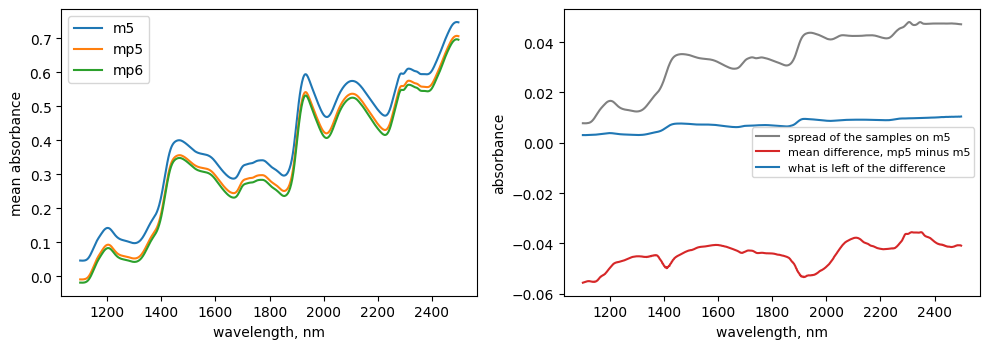

In [2]:
import json
import os
import sys

sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np
import prepare_calibration_transfer as PREP
import run_calibration_transfer as CT
from cmfqsar import spectrum as SP

if not (os.path.isfile(PREP.CORN) and os.path.isfile(PREP.TABLETS)):
    PREP.prepare()                      # the first run downloads 6.5 MB
data = PREP.load("corn")
x, S = CT.cut(data, *CT.SETS["corn"]["range"])     # S[instrument, sample, point]
names = [str(n) for n in data["property_names"]]
properties = list(CT.SETS["corn"]["properties"])
Y = data["properties"][:, [names.index(p) for p in properties]]
sd = Y.std(axis=0)
instruments = [str(i) for i in data["instruments"]]
step = float(x[1] - x[0])
print("corn: %d instruments (%s), %d samples, %d points from %g to %g nm" % (
    len(S), ", ".join(instruments), S.shape[1], len(x), x[0], x[-1]))
print("properties: " + ", ".join("%s (sd %.3f)" % (p, s) for p, s in zip(properties, sd)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for k, name in enumerate(instruments):
    ax[0].plot(x, S[k].mean(axis=0), label=name)
ax[0].set_xlabel("wavelength, nm")
ax[0].set_ylabel("mean absorbance")
ax[0].legend()
diff = S[1] - S[0]
ax[1].plot(x, (S[0] - S[0].mean(axis=0)).std(axis=0), color="0.5", label="spread of the samples on m5")
ax[1].plot(x, diff.mean(axis=0), color="C3", label="mean difference, mp5 minus m5")
ax[1].plot(x, (diff - diff.mean(axis=0)).std(axis=0), color="C0", label="what is left of the difference")
ax[1].set_xlabel("wavelength, nm")
ax[1].set_ylabel("absorbance")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

The left panel shows that the three instruments see nearly the same spectrum. The right panel
compares sizes. The grey curve is how much the samples differ from each other on `m5`: this is
the information that a model uses. The red curve is the difference between the two instruments,
averaged over the samples. It is as large as the grey curve, and it does not follow the samples:
it is one spectrum that `mp5` adds to every sample. The blue curve is what is left of the
difference when that one spectrum is taken off.

`CT.difference` takes the difference apart step by step for every pair of instruments: first the
mean difference, then an offset, a gain and a sloping baseline for every sample, then a shift of
the axis. It also fits a difference in resolution from the two mean spectra
(`SP.fit_width`). Every number is a root mean square of absorbance over the samples and the axis.

In [3]:
print("%-12s %8s %11s %16s %16s %10s %18s" % ("pair", "spread", "difference", "after the mean", "after per-sample",
                                              "shift, nm", "resolution diff., nm"))
for a in range(3):
    for b in range(a + 1, 3):
        d = CT.difference(S[a], S[b], x)
        print("%-12s %8.4f %11.4f %16.4f %16.4f %+10.2f %18.0f" % (
            instruments[a] + " to " + instruments[b], d["spread_of_the_samples"], d["difference"],
            d["after_the_mean_difference"], d["after_offset_gain_and_slope_per_sample"],
            d["shift_nm"], d["width_difference_nm"]))

pair           spread  difference   after the mean after per-sample  shift, nm resolution diff., nm


m5 to mp5      0.0357      0.0450           0.0077           0.0010      +0.50                  0
m5 to mp6      0.0357      0.0565           0.0076           0.0011      +0.80                  0
mp5 to mp6     0.0337      0.0122           0.0026           0.0003      +0.40                  0


Between `m5` and `mp5` the spectra of one sample differ by 0.045 (a root mean square). That is
more than the samples differ from each other on one instrument (0.036). When the mean difference is taken off, 0.008 is
left: the mean difference is 97 % of the squared difference. An offset, a gain and a sloping
baseline for every sample take the rest down to 0.001. The axis is shifted by 0.4 to 0.8 nm, which
is less than one step of the grid (2 nm), and the resolution does not differ at all.

So two instruments differ mostly by **one spectrum that is the same for every sample**. It is not
flat: the red curve has a shape along the axis. The plan item expected a difference in resolution;
these instruments do not have one. The last section of the notebook comes back to resolution.

## One split: a model fitted on `m5` reads the spectra of `mp5`

The cell draws the first split of the benchmark (the same seed): 60 samples to fit and 20 to
test. The model is the one of the benchmark: kernel ridge regression on the linear kernel of the
**slopes** of the spectra, after a broadening whose width is chosen with the ridge by five folds
inside the 60 samples, on the source instrument alone (`CT.fitted`). Then the 20 test samples are
read from their `mp5` spectra in five ways.

- **As measured**: nothing is done.
- **SNV** (standard normal variate): every spectrum, of the fit and of the test alike, has its
  own mean taken off and is divided by its own standard deviation along the axis. The model is
  fitted on the corrected spectra.
- **MSC** (multiplicative scatter correction): every spectrum is fitted as an offset plus a gain
  times one reference spectrum, here the mean spectrum of the 60 samples on the source, and both
  are taken off.
- **Each instrument centred**: the mean spectrum of the 20 test spectra is taken off and the
  mean spectrum of the 60 source spectra of the fit is put in its place. This uses the target
  spectra of the test samples together, but not their measured properties.
- **PDS with 8 standards** (piecewise direct standardisation, the standard method): 8 samples of
  the fit, chosen to cover the set, are measured on both instruments. For every point of the axis
  a small regression makes the source value from a window of target values. It needs those 8
  samples on the new instrument.

SNV and MSC are the reference of this notebook. They are what a chemometric model usually does
to every spectrum before anything else, they need nothing but the spectrum itself, and they
remove an offset and a gain, which is what one would expect two instruments to differ by.

error / sd                  moisture       oil   protein    starch      mean
within m5 (no change)          0.042     0.113     0.082     0.129     0.091
as measured                    4.364     3.175     1.991     3.429     3.240
SNV                            3.857     5.047     1.541     3.137     3.396
MSC                            3.851     4.855     1.537     3.242     3.371
each instrument centred        0.594     0.303     0.295     0.455     0.412
PDS, 8 standards               0.579     0.345     0.316     0.435     0.419


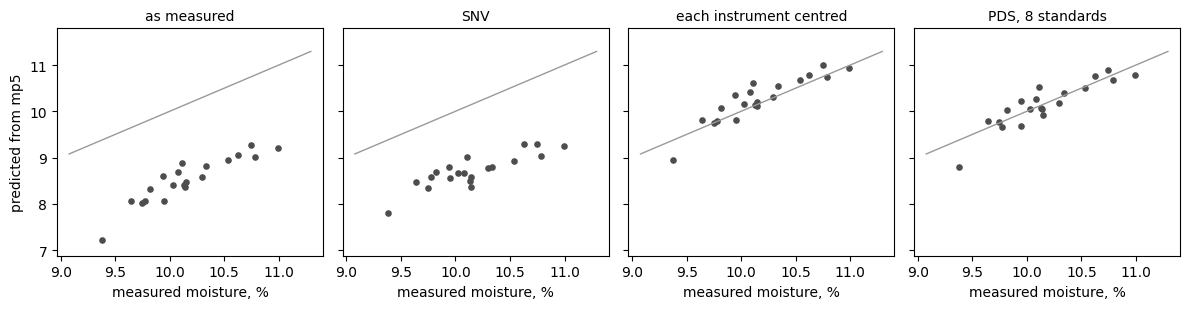

In [4]:
rng = np.random.default_rng(CT.SEED)                    # the first split of the benchmark
order = rng.permutation(len(Y))
fit, test = np.sort(order[:60]), np.sort(order[60:])
folds = [np.sort(f) for f in np.array_split(rng.permutation(len(fit)), CT.FOLDS)]
src, tgt = 0, 1                                         # m5 to mp5
reference = S[src][fit].mean(axis=0)
standards = fit[CT.kennard_stone(S[src][fit], CT.N_STANDARDS)]
loo = CT.pds_leave_one_out(S[src][standards], S[tgt][standards])

ways = ("as measured", "SNV", "MSC", "each instrument centred", "PDS, 8 standards")
pred = {w: np.zeros((len(test), len(properties))) for w in ways}
within = np.zeros((len(test), len(properties)))
for p in range(len(properties)):
    y = Y[fit, p]
    plain = CT.fitted(S[src][fit], y, step, "slope", "kernel", folds)
    within[:, p] = CT.predict(plain, S[src][test])
    Xt = S[tgt][test]
    pred["as measured"][:, p] = CT.predict(plain, Xt)
    for c in ("SNV", "MSC"):
        m = CT.fitted(CT.corrected(c, S[src][fit], reference), y, step, "slope", "kernel", folds)
        pred[c][:, p] = CT.predict(m, CT.corrected(c, Xt, reference))
    pred["each instrument centred"][:, p] = CT.predict(plain, Xt - Xt.mean(axis=0) + S[src][fit].mean(axis=0))
    half, rank = CT.pds_chosen(plain, Y[standards, p], loo)
    pds = CT.pds_fit(S[src][standards], S[tgt][standards], half, rank)
    pred["PDS, 8 standards"][:, p] = CT.predict(plain, CT.pds_apply(pds, Xt))


def errors(P):
    return np.sqrt(np.mean((P - Y[test]) ** 2, axis=0)) / sd


print("%-26s " % "error / sd" + " ".join("%9s" % p for p in properties) + "      mean")
for label, P in [("within m5 (no change)", within)] + list(pred.items()):
    e = errors(P)
    print("%-26s " % label + " ".join("%9.3f" % v for v in e) + "   %7.3f" % e.mean())

fig, ax = plt.subplots(1, 4, figsize=(12, 3.2), sharex=True, sharey=True)
for a, w in zip(ax, ("as measured", "SNV", "each instrument centred", "PDS, 8 standards")):
    a.scatter(Y[test, 0], pred[w][:, 0], s=14, color="0.3")
    lo, hi = Y[:, 0].min() - 0.3, Y[:, 0].max() + 0.3
    a.plot([lo, hi], [lo, hi], color="0.6", linewidth=1)
    a.set_title(w, fontsize=10)
    a.set_xlabel("measured moisture, %")
ax[0].set_ylabel("predicted from mp5")
ax[0].set_ylim(Y[:, 0].min() - 2.5, Y[:, 0].max() + 0.8)
plt.tight_layout()
plt.show()

Within `m5` the model has an error of 0.09 of the spread of the properties. Read on the `mp5`
spectra of the same 20 samples, the error is 3.2: three times worse than predicting the mean.
The first panel shows why. The predictions still follow the measured moisture, but they all lie
about 1.5 % too low. Most of the error is one bias, and the bias comes from the mean difference
of the two instruments.

SNV and MSC do not repair it (3.4 and 3.4). They take off an offset and a gain from every
spectrum, and the mean difference is not an offset or a gain: it has a shape along the axis, and
part of that shape stays after the correction. Centring each instrument takes exactly that one
spectrum off, and the error falls to 0.41. PDS with 8 standards gives 0.42 on this split, so here
the centring, which needs no standard, is as good as the standard method.

## Twenty splits, both sets, every pair of instruments

One split of 20 test samples is noisy. `run_calibration_transfer.py --scatter` repeats the cell
above over the 20 random splits of the benchmark, for every ordered pair of instruments of both
sets (six crossings of corn, two of tablets) and for two models: PLS on the plain spectra, which
is the usual chemometric model, and kernel ridge on the slopes. The splits and folds are those of
the benchmark, so the columns without a correction repeat its numbers. The column `target model`
is a model fitted on the target instrument itself: it is the floor of each crossing. The cell
reads the stored result; the stage takes about three minutes.

In [5]:
sc = json.load(open(os.path.join(CT.RESULTS, "scatter.json")))
columns = [("none|as measured", "as measured"), ("SNV|as measured", "SNV"), ("MSC|as measured", "MSC"),
           ("none|each instrument centred", "centred"), ("SNV|each instrument centred", "SNV+centred"),
           ("none|PDS", "PDS 8 std."), ("none|fitted on the target", "target model")]
for case, title in (("pls|plain", "PLS on the plain spectra"), ("kernel|slope", "kernel ridge on the slopes")):
    print(title + ": error / sd, mean over 20 splits and the properties")
    print("   %-22s" % "source to target" + "".join("%13s" % n for _, n in columns))
    for which, s in sc["sets"].items():
        for key, node in s["crossing"][case].items():
            a, b = (int(v) for v in key.split("->"))
            label = "%s, %s to %s" % (which, s["instruments"][a], s["instruments"][b])
            print("   %-22s" % label + "".join("%13.3f" % node[k]["mean"] for k, _ in columns))
    print()

PLS on the plain spectra: error / sd, mean over 20 splits and the properties
   source to target        as measured          SNV          MSC      centred  SNV+centred   PDS 8 std. target model
   corn, m5 to mp5               2.791        3.165        3.033        0.513        0.576        0.541        0.440
   corn, m5 to mp6               2.846        3.235        3.125        0.543        0.610        0.570        0.454
   corn, mp5 to m5               3.521        2.584        2.790        0.585        0.666        0.544        0.120
   corn, mp5 to mp6              1.327        1.493        1.555        0.526        0.561        0.493        0.454
   corn, mp6 to m5               3.219        2.762        2.821        0.613        0.680        0.572        0.120
   corn, mp6 to mp5              1.095        1.524        1.499        0.521        0.595        0.518        0.440
   tablets, 1 to 2               1.754        2.149        1.875        0.472        0.433        0.407 

The twenty splits agree with the one split. Read as measured, the target spectra give an error of
0.9 to 3.5 times the spread. SNV and MSC leave it between 1.0 and 3.2: better than nothing on some
crossings and worse on others, and never usable. Centring each instrument gives 0.49 to 0.61 for
corn and 0.33 to 0.47 for the tablets. PDS with 8 standards gives 0.45 to 0.57 and 0.31 to 0.41.

The differences that matter, paired over the 20 splits, with 95 % bootstrap intervals. Each is
the first error minus the second, for the error averaged over the crossings of a set.

In [6]:
show = [("SNV|as measured minus none|as measured", "SNV minus nothing"),
        ("MSC|as measured minus none|as measured", "MSC minus nothing"),
        ("none|each instrument centred minus SNV|as measured", "centred minus SNV"),
        ("SNV|each instrument centred minus none|each instrument centred", "SNV then centred, minus centred"),
        ("none|each instrument centred minus none|PDS", "centred minus PDS with 8 standards"),
        ("within, SNV minus none", "within the source: SNV minus nothing")]
for case, title in (("pls|plain", "PLS on the plain spectra"), ("kernel|slope", "kernel ridge on the slopes")):
    print(title)
    for key, label in show:
        cells = []
        for which, s in sc["sets"].items():
            v = s["pairs"][case][key]
            cells.append("%s %+.3f [%+.3f, %+.3f]" % (which, v["mean"], v["low"], v["high"]))
        print("   %-38s " % label + "   ".join(cells))
    print()

PLS on the plain spectra
   SNV minus nothing                      corn -0.006 [-0.145, +0.131]   tablets -0.617 [-1.337, +0.024]
   MSC minus nothing                      corn +0.004 [-0.129, +0.128]   tablets -0.448 [-1.245, +0.428]
   centred minus SNV                      corn -1.910 [-2.000, -1.814]   tablets -1.390 [-2.078, -0.789]
   SNV then centred, minus centred        corn +0.064 [+0.050, +0.080]   tablets -0.043 [-0.129, +0.036]
   centred minus PDS with 8 standards     corn +0.011 [-0.002, +0.024]   tablets +0.047 [+0.019, +0.079]
   within the source: SNV minus nothing   corn +0.091 [+0.077, +0.105]   tablets -0.009 [-0.012, -0.006]

kernel ridge on the slopes
   SNV minus nothing                      corn -0.132 [-0.209, -0.065]   tablets -0.398 [-0.624, -0.192]
   MSC minus nothing                      corn -0.133 [-0.210, -0.064]   tablets -0.372 [-0.573, -0.182]
   centred minus SNV                      corn -1.415 [-1.480, -1.344]   tablets -1.127 [-1.936, -0.545]
  

**Question 3: no.** The correction of every spectrum by itself does not repair the crossing.
Against doing nothing, SNV changes the error of PLS on corn by -0.006 [-0.145, +0.131]. It helps
kernel ridge on the slopes a little (-0.13 for corn, -0.40 for the tablets), but the error stays
above 1. Centring each instrument is better than SNV by 1.4 to 1.9 for corn and by 1.1 to 1.4
for the tablets, and every interval is far from zero. The reference is clearly beaten.

SNV before the centring adds nothing. On corn it makes the error larger by +0.06, with an
interval that excludes zero. On the tablets the difference is not separated from zero. The same
is seen within one instrument, where no transfer is needed: SNV raises the error on corn by 0.09
to 0.10 and lowers it on the tablets by less than 0.01. So the overall level and scale of a corn
spectrum carry part of the information about its properties, and SNV removes them.

**Question 4.** The standards still win, by a little. With kernel ridge on the slopes, centring
minus PDS with 8 standards is +0.020 [+0.006, +0.034] for corn and +0.025 [+0.004, +0.048] for
the tablets. With PLS on the plain spectra it is +0.011 [-0.002, +0.024] for corn, which is not
separated from zero, and +0.047 for the tablets.

## What the centring costs

The centring assumes that the test samples have the mean spectrum of the samples of the fit.
They do not have it exactly, and the model reads the difference of the two means as a
difference in the property. This cost can be measured without a second instrument: centre the
test spectra of the **same** instrument and see how much the error rises. The benchmark stores
it, and it also stores PDS with 16 standards.

In [7]:
tr = json.load(open(os.path.join(CT.RESULTS, "transfer.json")))
print("kernel ridge on the slopes, within one instrument: error / sd, mean over the properties")
print("   %-14s %12s %26s %8s" % ("instrument", "as measured", "test spectra centred", "test"))
for which, s in tr["sets"].items():
    for a, by_p in s["within"].items():
        e = [np.mean([by_p[str(p)]["kernel"]["slope"][v]["mean"] / s["property_sd"][p] for p in range(len(s["properties"]))])
             for v in ("as measured", "each instrument centred")]
        print("   %-14s %12.3f %26.3f %8d" % ("%s, %s" % (which, s["instruments"][int(a)]), e[0], e[1], s["test"]))
print()
print("PDS with 8 and with 16 standards, kernel ridge on the slopes, mean over the crossings:")
for which, s in sc["sets"].items():
    t = tr["sets"][which]
    rel = lambda v: np.mean([np.mean([t["crossing"][k][str(p)]["kernel"]["slope"][v]["mean"] / t["property_sd"][p]
                                      for p in range(len(t["properties"]))]) for k in t["crossing"]])
    print("   %-8s each instrument centred %.3f   PDS 8 standards %.3f   PDS 16 standards %.3f" % (
        which, rel("each instrument centred"), rel("piecewise direct standardisation"),
        rel("piecewise direct standardisation, more standards")))

kernel ridge on the slopes, within one instrument: error / sd, mean over the properties
   instrument      as measured       test spectra centred     test
   corn, m5              0.100                      0.221       20
   corn, mp5             0.425                      0.471       20
   corn, mp6             0.398                      0.445       20
   tablets, 1            0.236                      0.261      500
   tablets, 2            0.240                      0.265      500

PDS with 8 and with 16 standards, kernel ridge on the slopes, mean over the crossings:
   corn     each instrument centred 0.509   PDS 8 standards 0.489   PDS 16 standards 0.472
   tablets  each instrument centred 0.351   PDS 8 standards 0.326   PDS 16 standards 0.303


Within one instrument, centring the test spectra raises the error of `m5` from 0.100 to 0.221, of
`mp5` from 0.425 to 0.471, and of the tablet instruments from 0.236 to 0.261 and from 0.240 to
0.265. No instrument changed in these numbers, so this is the cost of the centring alone. When the
mean spectra of the fit and of the test are made equal, the mean prediction of the test samples
becomes the mean property of the samples of the fit. The two means differ by chance, by about the
standard deviation of the property times the square root of 1/(samples of the fit) + 1/(samples of
the test). So the cost falls when more samples are on both sides.

This cost explains most of what the centring loses against PDS. The gap is about 0.02 for corn
(0.509 against 0.489) and 0.025 for the tablets (0.351 against 0.326). That is no larger than the
cost of the centring within one instrument: 0.05 to 0.12 for corn and 0.025 for the tablets.
Standards do not pay this cost, and 16 standards gain a little more (0.472 and 0.303).

## A difference in resolution

The plan item expected the instruments to differ in resolution. Part 1 found that they do not
(the fitted difference is 0). So the cell makes one: the test spectra of `m5` are broadened by a
Gaussian of 16 nm, as a coarser instrument would record them. Two Gaussian broadenings add as
squares, so a model fitted on source spectra broadened by the same 16 nm reads the coarser
spectra at one common width. `SP.fit_width` finds the difference from the two mean spectra,
without a standard.

In [8]:
coarse = SP.smoothed(S[src][test], step, 16.0)
signed, _ = SP.fit_width(S[src][fit].mean(axis=0), coarse.mean(axis=0), x, CT.TRIED_WIDTHS)
print("fitted difference in resolution: %.0f nm (the true one is 16 nm)" % signed)
wider = SP.smoothed(S[src][fit], step, max(signed, 0.0))
rows = {"read as they are": [], "each instrument centred": [], "widths matched": []}
for p in range(len(properties)):
    y = Y[fit, p]
    plain = CT.fitted(S[src][fit], y, step, "slope", "kernel", folds)
    rows["read as they are"].append(CT.rmse(CT.predict(plain, coarse), Y[test, p]) / sd[p])
    rows["each instrument centred"].append(CT.rmse(CT.predict(plain, coarse - coarse.mean(axis=0) + S[src][fit].mean(axis=0)), Y[test, p]) / sd[p])
    matched = CT.fitted(wider, y, step, "slope", "kernel", folds)
    rows["widths matched"].append(CT.rmse(CT.predict(matched, coarse), Y[test, p]) / sd[p])
print("error / sd, mean over the properties (within m5 with no broadening: %.3f)" % errors(within).mean())
for k, v in rows.items():
    print("   %-26s %.3f" % (k, np.mean(v)))

fitted difference in resolution: 16 nm (the true one is 16 nm)


error / sd, mean over the properties (within m5 with no broadening: 0.091)
   read as they are           3.108
   each instrument centred    0.713
   widths matched             0.152


`SP.fit_width` finds the difference of 16 nm from the two mean spectra, with no standard. Read
as they are, the coarser spectra give an error of 3.1. Centring does not help much (0.71),
because a difference in resolution changes each spectrum in its own way, and not by one common
spectrum. With the widths matched the error is 0.15. That is close to the 0.09 of the instrument
itself, and the rest is the information that the broadening removed. In the benchmark the same
holds over 20 splits and all sources: 2.96, 0.71 and 0.33 for corn at 16 nm. So the kernel of
two broadened spectra does what the plan expected. These two sets simply do not need it.

## What this shows and what it does not

**What it shows.**

- Two near-infrared instruments differ mostly by one spectrum that is common to all samples: 97 %
  of the squared difference between two corn instruments. They do not differ in resolution, and
  the shift is less than one step of the grid.
- Without treatment a model is useless on another instrument: its error is 0.9 to 3.5 times the
  spread of the property.
- The usual correction of every spectrum by itself, SNV or MSC, does not repair this. It removes
  an offset and a gain, and the difference between the instruments has a shape along the axis.
- Centring each instrument on its own mean spectrum needs no transfer standard. It brings the
  error to 0.49 to 0.61 for corn and 0.33 to 0.47 for the tablets. That is within 0.01 to 0.05 of
  PDS with 8 standards measured on both instruments.
- The gain is in this treatment of the spectra and not in the model. The benchmark finds that PLS
  and kernel ridge on the same rows agree within 2 to 4 %.
- A difference in resolution, when there is one, is repaired by matched widths. The difference
  can be fitted from the two mean spectra without a standard.

**What it does not show.**

- That the centring works when the new samples differ from the samples of the fit in their
  average composition. The centring sets the mean prediction to the mean of the fit. A new batch
  with more moisture on average would be predicted with the old mean. In that case measure
  standards on both instruments.
- That it works with few new samples. With 20 test samples the centring alone raises the error of
  the most precise instrument from 0.10 to 0.22.
- That matched widths work on a real pair of instruments of different resolution. The difference
  here is simulated.
- Anything about other kinds of spectra. Both sets are near-infrared spectra with broad bands.

The practical rule: when a model moves to a new instrument and many new samples are measured
together, centre each instrument on its own mean spectrum before anything else. A correction of
every spectrum by itself is not a substitute. When the new samples are few, or may differ in
composition, measure transfer standards.